# Notebook to build the script of Circonscription Map generation

## For 28th of November
1. project France Metropol map from INSEE in EPSG:2154
2. Perform Correction, check, and simplify_coverage
3. Check Size of file
4. Append with SciencePo Service Map (Only COM)
5. Project result in EPSG:4326
6. Append DROM
7. Check few cases (at borders of circo)
8. check size of file

## Retrieve Map from INSEE

In [1]:
import requests, geopandas as gpd

url = "https://www.data.gouv.fr/api/1/datasets/r/dbf42fce-a563-412e-9db1-1f7ab453c2ef"
r = requests.get(url)
#read zip file content into a GeoDataFrame
gpf_insee = gpd.read_file(r.content)
#return 5 first rows of the GeoDataFrame
gpf_insee.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."


In [4]:
#test the Coordinate Reference System (CRS) of the GeoDataFrame
gpf_insee.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
gpf_insee.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  558 non-null    str     
 1   dep       558 non-null    str     
 2   libelle   558 non-null    str     
 3   geometry  558 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 37.7 KB


In [2]:
gpf_insee.is_valid_coverage()

False

In [84]:
type(gpf_insee)

geopandas.geodataframe.GeoDataFrame

In [47]:
gpf_insee_repaired = gpf_insee.copy()
gpf_insee_repaired.geometry = gpf_insee_repaired.geometry.apply(repair_with_area_check)
gpf_insee_repaired.is_valid_coverage()

False

In [48]:
gpf_insee_repaired

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-54.60236 2.33356, -54.60242 2..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-51.93691 4.46648, -51.93667 4..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-61.00495 14.57791, -61.00492 ..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-61.12889 14.63162, -61.1289 1..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-61.03945 14.64265, -61.0394 14.6425..."
...,...,...,...,...
553,0502,05,Hautes-Alpes - 2e circonscription,"MULTIPOLYGON (((6.23277 44.46288, 6.24026 44.4..."
554,0401,04,Alpes-de-Haute-Provence - 1re circonscription,"MULTIPOLYGON (((6.84988 43.9141, 6.83595 43.91..."
555,4204,42,Loire - 4e circonscription,"MULTIPOLYGON (((4.54255 45.24218, 4.53626 45.2..."
556,0703,07,Ardèche - 3e circonscription,"POLYGON ((4.05709 44.36415, 4.05709 44.36415, ..."


### Simplify Map drawing to reduce Map size

1. convert CRS from EPSG:4326 to EPSG:2154 (RGF93 / Lambert-93) : metre based system and standard for France

Only Metropolitan France will be converted

Select Metropolitan France for projection to Lambert-93

In [76]:
gpf_insee_3857 = gpf_insee.to_crs(epsg=3857)
gpf_insee_3857.head(5)

,id_circo,dep,libelle,geometry
0,97302,973,Guyane - 2e circonscription,"MULTIPOLYGON (((-6078306.99 259842.11, -607831..."
1,97301,973,Guyane - 1re circonscription,"MULTIPOLYGON (((-5781589.848 497711.173, -5781..."
2,97201,972,Martinique - 1re circonscription,"MULTIPOLYGON (((-6791039.757 1640603.641, -679..."
3,97202,972,Martinique - 2e circonscription,"MULTIPOLYGON (((-6804837.228 1646781.86, -6804..."
4,97203,972,Martinique - 3e circonscription,"POLYGON ((-6794879.991 1648050.814, -6794874.6..."


2. In the case of adjacent polygons we use simplify_coverage : warning geometry might need cleaning
```
from shapely import make_valid

# 1. Drop missing/empty and keep only Polygon / MultiPolygon
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
gdf = gdf[gdf.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

# 2. Repair invalid geometries and remove zero-area artifacts
gdf["geometry"] = gdf.geometry.apply(make_valid)
gdf = gdf[~gdf.geometry.is_empty & (gdf.geometry.area > 0)].copy()

# 3. Simplify coverage with a conservative tolerance first
simplified = gdf.geometry.simplify_coverage(tolerance=0.001)
```

In [77]:
gpf_insee_3857_simplified = gpf_insee_3857[gpf_insee_3857.geometry.notna()].copy()

First we test if the geometry is valid

In [78]:
gpf_insee_3857_simplified.geometry.is_valid_coverage(gap_width=10)

False

check the problem of coverage

In [79]:
coverage_pb_type = gpf_insee_3857_simplified.invalid_coverage_edges().geom_type[gpf_insee_3857_simplified.invalid_coverage_edges().count_geometries() != 1].unique()
# the ','.join(map(str,a)) will print all elements of the list above separated by comma
print(f'problem of coverage (over-lapping polygons or mismatched edges) detected in the geodataframes are of type {','.join(map(str,coverage_pb_type))}')

problem of coverage (over-lapping polygons or mismatched edges) detected in the geodataframes are of type MultiLineString


In [80]:
import shapely
test_clean = gpf_insee_3857_simplified.copy()
test_clean.geometry = shapely.coverage_clean(test_clean.geometry,merge_strategy='longest_border')
test_clean.is_valid_coverage(gap_width=10)


False

Check the reasons why the geometry is not valid

In [81]:
print(gpf_insee_3857_simplified.geometry.is_valid_reason())

0                                         Valid Geometry
1                                         Valid Geometry
2                                         Valid Geometry
3                                         Valid Geometry
4                                         Valid Geometry
                             ...                        
553                                       Valid Geometry
554    Self-intersection[747701.925307082 5483968.441...
555                                       Valid Geometry
556                                       Valid Geometry
557                                       Valid Geometry
Length: 558, dtype: str


Follow the process : https://www.geospatialdatatesting.org/spatial-test-pattern-design-implementation/geometry-validation-patterns/repairing-invalid-geometries-with-make-valid-safely/

In [82]:
# return all rows with a result different than "valid geometry"
df_errors = gpf_insee_3857_simplified.geometry.is_valid_reason()[gpf_insee_3857_simplified.geometry.is_valid_reason() != "Valid Geometry"]
# retrieve first part of the message and return unique values
errors_type = df_errors.str.split(pat="[",expand=True)[0].unique()
print(errors_type)

<ArrowStringArray>
[                   'Self-intersection',
 'Too few points in geometry component',
                        'Nested shells',
               'Ring Self-intersection']
Length: 4, dtype: str


Zoom on the "Too few points in geometry component" error

In [83]:
df_errors [df_errors.str.split(pat="[",expand=True)[0] == "Too few points in geometry component"]

192    Too few points in geometry component[643880.55...
535    Too few points in geometry component[580057.34...
dtype: str

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

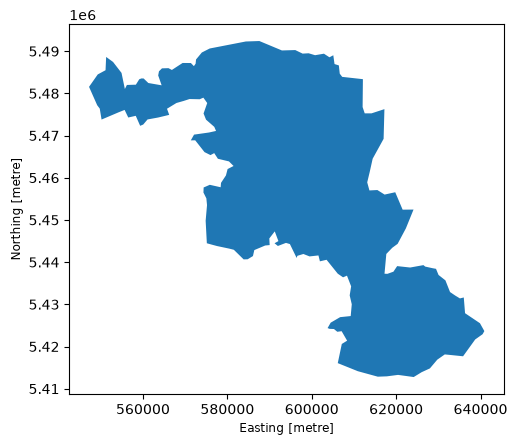

In [84]:
gpf_insee_3857_simplified.loc[[535]].plot()

In [85]:
gpf_insee_3857_simplified.geometry[gpf_insee_3857_simplified.geometry.is_valid_reason() != "Valid Geometry"].make_valid()

19     MULTIPOLYGON (((634481.924 5646816.987, 634481...
22     MULTIPOLYGON (((613169.755 5632562.031, 613169...
24     GEOMETRYCOLLECTION (MULTIPOLYGON (((156139.667...
36     MULTIPOLYGON (((-71059.251 5599613.032, -71059...
42     MULTIPOLYGON (((-11473.002 6061609.261, -11473...
                             ...                        
544    MULTIPOLYGON (((-72779.159 6062613.078, -72779...
546    GEOMETRYCOLLECTION (POLYGON ((-321574.574 6059...
548    MULTIPOLYGON (((-457416.532 6097335.562, -4560...
549    MULTIPOLYGON (((-474065.614 6169029.649, -4741...
554    MULTIPOLYGON (((728198.772 5430802.255, 728573...
Length: 71, dtype: geometry

Function to repair and normalize the type of geometry -> transform Geometry Collection into Polygons and Multipolygons

In [86]:
from shapely import make_valid
from shapely.geometry import MultiPolygon, Polygon
from shapely.geometry.base import BaseGeometry


def repair_polygonal(geom: BaseGeometry) -> BaseGeometry:
    """make_valid, then keep only the polygonal parts of the result."""
    if geom.is_valid:
        return geom

    fixed = make_valid(geom)

    if fixed.geom_type == "GeometryCollection":
        parts = [g for g in fixed.geoms if g.geom_type in ("Polygon", "MultiPolygon")]
        if not parts:
            raise ValueError("repair produced no polygonal geometry")
        fixed = parts[0] if len(parts) == 1 else MultiPolygon(
            [p for g in parts for p in (g.geoms if g.geom_type == "MultiPolygon" else [g])]
        )
    if fixed.is_empty:
        raise ValueError("repair produced an empty geometry")
    return fixed

Apply the function to geodataframe

In [87]:
gpf_insee_3857_simplified_fixed = gpf_insee_3857_simplified.copy()
gpf_insee_3857_simplified_fixed.geometry = gpf_insee_3857_simplified.geometry.apply(repair_polygonal)

function to test that the geometry hasn't been modified too much

In [88]:
AREA_TOLERANCE = 1e-9        # relative


def repair_with_area_check(geom: BaseGeometry, tol: float = AREA_TOLERANCE):
    before = geom.area
    fixed = repair_polygonal(geom)
    after = fixed.area

    if before > 0:
        drift = abs(after - before) / before
        if drift > tol:
            raise ValueError(
                f"repair changed area by {drift:.2%} "
                f"({before:.6f} -> {after:.6f})"
            )
    return fixed

In [89]:
gpf_insee_3857_simplified_fixed.geometry = gpf_insee_3857_simplified.geometry.apply(repair_with_area_check)

In [90]:
gpf_insee_3857_simplified_fixed.is_valid_coverage(gap_width=10)

False

In [91]:
gpf_insee_3857_simplified_fixed.invalid_coverage_edges(gap_width=10)

0                                       LINESTRING EMPTY
1                                       LINESTRING EMPTY
2                                       LINESTRING EMPTY
3                                       LINESTRING EMPTY
4                                       LINESTRING EMPTY
                             ...                        
553    MULTILINESTRING ((694662.114 5534995.343, 6938...
554    MULTILINESTRING ((728573.748 5431820.004, 7281...
555    MULTILINESTRING ((491993.766 5664982.462, 4888...
556    MULTILINESTRING ((451175.64 5524234.494, 45014...
557    MULTILINESTRING ((683455.047 5560748.69, 68283...
Length: 558, dtype: geometry

In [92]:
# return all rows with a result different than "valid geometry"
df_errors = gpf_insee_3857_simplified_fixed.geometry.is_valid_reason()[gpf_insee_3857_simplified_fixed.geometry.is_valid_reason() != "Valid Geometry"]
# retrieve first part of the message and return unique values
#errors_type = df_errors.str.split(pat="[",expand=True)[0].unique()
#print(errors_type)

In [93]:
gpf_insee_3857_simplified_fixed = gpf_insee_3857_simplified_fixed.simplify_coverage(tolerance=100000)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

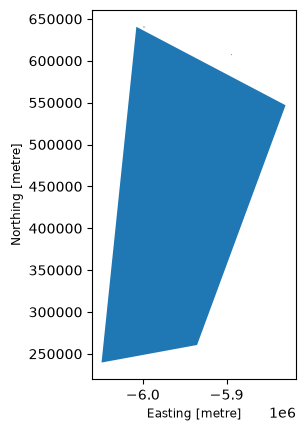

In [94]:
gpf_insee_3857_simplified_fixed.iloc[[0]].plot()

In [95]:
gpf_insee_3857_simplified = gpf_insee_3857_simplified[gpf_insee_3857_simplified.geometry.type.isin(["Polygon","MultiPolygon"])].copy()

In [96]:
from shapely.validation import make_valid
#gpf_insee_3857_simplified = gpf_insee_3857_simplified.geometry.apply(make_valid)
gpf_insee_3857_simplified = gpf_insee_3857_simplified[gpf_insee_3857_simplified.geometry.notna() & gpf_insee_3857_simplified.geometry.area > 0].copy()

In [97]:
set(gpf_insee_3857_simplified.geometry.type)

{'MultiPolygon', 'Polygon'}

In [98]:
import shapely
list_num = []
for i in range(len(gpf_insee_3857_simplified)):
    list_num.append(shapely.get_num_coordinates(gpf_insee_3857_simplified.geometry[i]))

In [99]:
for i in range(len(list_num)):
    if list_num[i] == min(list_num):
        print(i)

134


In [100]:
gpf_insee_3857_simplified.iloc[134]

id_circo                                                 9209
dep                                                        92
libelle                   Hauts-de-Seine - 9e circonscription
geometry    POLYGON ((248064.03288606368 6245873.309682483...
Name: 134, dtype: object

In [101]:
gpf_insee_3857_simplified.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id_circo  558 non-null    str     
 1   dep       558 non-null    str     
 2   libelle   558 non-null    str     
 3   geometry  558 non-null    geometry
dtypes: geometry(1), str(3)
memory usage: 37.7 KB


In [102]:
gpf_insee_3857_simplified = gpf_insee_3857_simplified.simplify_coverage(tolerance=0.001)

GEOSException: IllegalArgumentException: point array must contain 0 or >1 elements


### Tests few cases at circonscription border

## Retrieve COM (Communes D'Outre Mer) from ArcGIS Science PO service

### Download map of COM from Science PO service and change CRS (Coordinate Reference System)

## Concat Maps

## Export File to designated folder